# Détection d'émotions dans un texte

**Nom :** Aya Moussa · **Cours :** NLP — Projet 2026 · **Date :** octobre 2026

Classification de l'émotion exprimée dans un texte court, à partir du corpus `dair-ai/emotion`
(6 classes : sadness, joy, love, anger, fear, surprise).




> **Problème :** classer automatiquement un tweet parmi six émotions (tristesse, joie, amour, colère, peur, surprise).  
> **Corpus :** dair-ai/emotion — 20 000 tweets en anglais, split officiel 16 000 / 2 000 / 2 000.  
> **Modèles comparés :** baseline naïve, régression logistique, SVM linéaire (TF-IDF), DistilBERT fine-tuné.  
> **Meilleur résultat :** DistilBERT, macro-F1 0,871 sur le test ; SVM proche à 0,830.  
> **Observation principale :** le prétraitement standard (lemmatisation, suppression des stopwords) dégrade les performances par rapport au texte brut.

## Dépendances

```
pip install datasets transformers torch scikit-learn nltk matplotlib seaborn pandas
```



In [ ]:
# Imports et graine aléatoire globale
import re, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

pd.set_option("display.width", 140)
COLORS = ['#4C72B0', '#DD8452', '#55A868', '#C44E52', '#8172B2', '#937860']
print("Environnement prêt. SEED =", SEED)


## 1. Introduction et problématique

**Problème.** Identifier automatiquement l'émotion exprimée dans un tweet parmi six classes : tristesse, joie, amour, colère, peur, surprise.

**Difficulté.** La négation inverse le sens sans changer le vocabulaire. Les classes rares risquent d'être ignorées si la métrique est mal choisie.

**Problématique.** Quelles approches, du plus simple au plus avancé, permettent de classer l'émotion d’un texte court sur un corpus déséquilibré, et leur gain justifie-t-il leur coût ?

**Cadre.** Baseline naïve, classifieurs TF-IDF, transformer DistilBERT. Métrique : F1-macro.

## 2. État de l'art

La détection d'émotions dans le texte est une branche de l'analyse de sentiment.
Elle vise des catégories fines (joie, colère, peur) plutôt qu'une simple polarité
positive ou négative. Trois familles d'approches se sont succédé.

**Lexiques et règles.** Les premiers systèmes comptent, dans la phrase, les mots
figurant dans un dictionnaire d'émotions comme LIWC ou NRC. Kušen et al. (2017)
comparent trois de ces lexiques et montrent que leurs performances varient selon
l'émotion visée : NRC détecte le mieux la colère et la peur, un autre la tristesse.
Chez Saravia et al. (2018), LIWC obtient 0,35 de F1, le score le plus bas de leur
comparaison. Ces méthodes échouent sur le contexte : la phrase « meeting him should
have been a good idea » exprime une déception mais sera classée positive, car le
mot « good » est étiqueté positif dans le dictionnaire. Elles ne gèrent pas non plus
la négation, et leur vocabulaire figé ne suit pas l'évolution de la langue.

**Apprentissage classique.** On transforme le texte en vecteurs, puis un modèle
apprend les régularités. Saravia et al. (2018) comparent ces représentations sur
huit émotions : sac de mots 0,57, n-grammes 0,61, et 0,63 en pondérant par TF-IDF.
La pondération améliore systématiquement les résultats. Alotaibi (2019) rapporte sur
le corpus ISEAR que la régression logistique dépasse SVM, KNN et XG-Boost, avec
85 % de F1. La limite est structurelle : l'ordre des mots est perdu, donc une
négation n'est pas détectée. Et les classes rares s'effondrent, avec 0,41 contre
0,83 pour la classe majoritaire chez Saravia et al.

**Transformers.** Un modèle pré-entraîné sur de grands corpus est réentraîné sur la
tâche. Ses représentations dépendent du contexte, ce qui devait résoudre le problème
de la négation. Huang et al. (2019) atteignent 0,815 de F1 avec BERT sur le corpus
EmotionLines. Acheampong et al. (2021) relèvent trois limites reconnues : les mots
hors vocabulaire, le coût de calcul, et le surapprentissage sur les petits corpus.

**Métrique.** Le F1 domine le domaine. Saravia et al. (2018) le justifient
explicitement par la nature déséquilibrée des corpus d'émotions, où l'accuracy
masquerait l'abandon des classes rares.

**Limites du domaine.** Plaza-del-Arco et al. (2024) ont analysé 154 publications
sur dix ans. Ils relèvent que la plupart des travaux ne précisent ni qui a produit
ni qui a annoté les données, que les taxonomies employées sont trop larges — la
culpabilité et la solitude tombent toutes deux sous « tristesse » — et que les
corpus sont presque tous anglophones.

**Positionnement de ce travail.** Les modèles de référence de Saravia et al. sont
répliqués sur l'échantillon diffusé, puis étendus à un transformer, absent de leur
comparaison puisque BERT paraît au moment de leur publication. Trois choix
distinguent ce travail. Le prétraitement est comparé expérimentalement sur trois
variantes, au lieu d'être appliqué par convention. Les limites de l'annotation par
hashtags sont mesurées et non seulement mentionnées, ce qui répond au reproche de
Plaza-del-Arco et al. Et la capacité des modèles à traiter la négation est testée
directement, au-delà du score global.

## 3. Données


### 3.1 Présentation du corpus

Le corpus `dair-ai/emotion` provient de Saravia et al. (2018, EMNLP). Il est constitué de messages
courts en anglais issus de Twitter, étiquetés par **supervision distante** : l'étiquette provient
du hashtag émotionnel posé par l'auteur du tweet, sans relecture humaine. Les auteurs qualifient
eux-mêmes ces étiquettes de bruitées.

| Indice | 0 | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|---|
| Émotion | sadness | joy | love | anger | fear | surprise |

Découpage officiel fixe : 16 000 / 2 000 / 2 000. Licence : usage éducatif et recherche.

**Limite à retenir dès maintenant.** Le texte diffusé est déjà normalisé par les auteurs
(minuscules, sans URL ni mentions), ce qui prive le corpus des emojis et de la ponctuation
expressive, deux marqueurs émotionnels forts.


In [3]:
from datasets import load_dataset

ds = load_dataset("dair-ai/emotion", "split")
labels = ds["train"].features["label"].names

train = pd.DataFrame(ds["train"])
val   = pd.DataFrame(ds["validation"])
test  = pd.DataFrame(ds["test"])

print("Classes :", labels)
print(f"train {train.shape[0]} | validation {val.shape[0]} | test {test.shape[0]}")
print()
print(train.head(5).to_string(index=False))


Classes : ['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']
train 16000 | validation 2000 | test 2000

                                                                                                        text  label
                                                                                     i didnt feel humiliated      0
i can go from feeling so hopeless to so damned hopeful just from being around someone who cares and is awake      0
                                                            im grabbing a minute to post i feel greedy wrong      3
                i am ever feeling nostalgic about the fireplace i will know that it is still on the property      2
                                                                                        i am feeling grouchy      3


**Interprétation.** Le découpage officiel est respecté : 16 000, 2 000 et 2 000 exemples. Les textes sont courts, en minuscules et sans ponctuation, ce qui confirme la normalisation effectuée par les auteurs.

### 3.2 Exploration des données (EDA)


#### 3.2.1 Distribution des classes

On compte les exemples de chaque émotion. C'est cette mesure qui décide de la métrique
d'évaluation : sur un corpus déséquilibré, l'accuracy récompense un modèle qui ignore les
classes rares.


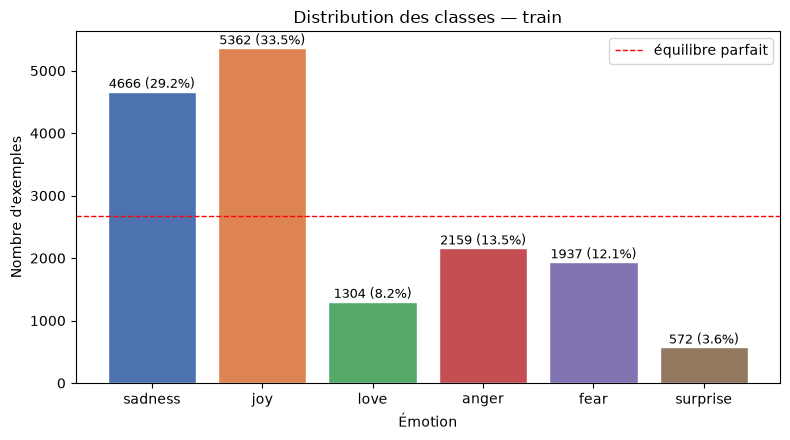

Classe la plus fréquente : joy (33.5 %)
Classe la plus rare      : surprise (3.6 %)
Ratio max/min            : 9.4 pour 1
Accuracy d'un modele qui predit toujours la classe majoritaire : 33.5 %


In [4]:
counts = train["label"].value_counts().sort_index()
total  = counts.sum()

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar([labels[i] for i in counts.index], counts.values, color=COLORS, edgecolor="white")
for b, c in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 60,
            f"{c} ({c/total*100:.1f}%)", ha="center", fontsize=9)
ax.axhline(total/len(labels), color="red", ls="--", lw=1, label="équilibre parfait")
ax.set_title("Distribution des classes — train")
ax.set_xlabel("Émotion"); ax.set_ylabel("Nombre d'exemples")
ax.legend(); plt.tight_layout(); plt.show()

ratio = counts.max() / counts.min()
print(f"Classe la plus fréquente : {labels[counts.idxmax()]} ({counts.max()/total*100:.1f} %)")
print(f"Classe la plus rare      : {labels[counts.idxmin()]} ({counts.min()/total*100:.1f} %)")
print(f"Ratio max/min            : {ratio:.1f} pour 1")
print(f"Accuracy d'un modele qui predit toujours la classe majoritaire : {counts.max()/total*100:.1f} %")


**Interprétation.** Le corpus est fortement déséquilibré : joy représente 33,5 % des exemples, surprise seulement 3,6 %, soit un ratio de 9,4:1. L'accuracy est donc trompeuse et le F1-macro est retenu comme métrique principale. Les classifieurs utiliseront `class_weight="balanced"` pour compenser ce déséquilibre.

#### 3.2.2 Stabilité du découpage

Si les trois splits n'avaient pas la même distribution, les scores mesurés sur la validation et
sur le test ne seraient pas comparables.


In [5]:
stab = pd.DataFrame({
    nom: (df["label"].value_counts(normalize=True).sort_index() * 100).round(1).values
    for nom, df in [("train", train), ("validation", val), ("test", test)]
}, index=labels)
print("Répartition des classes par split (%)\n")
print(stab.to_string())
print(f"\nÉcart maximal entre splits : {(stab.max(axis=1) - stab.min(axis=1)).max():.1f} points")


Répartition des classes par split (%)

          train  validation  test
sadness    29.2        27.5  29.0
joy        33.5        35.2  34.8
love        8.2         8.9   8.0
anger      13.5        13.8  13.8
fear       12.1        10.6  11.2
surprise    3.6         4.0   3.3

Écart maximal entre splits : 1.7 points


**Interprétation.** Les trois splits présentent des proportions très proches : le découpage officiel est stratifié. Les scores obtenus sur la validation et sur le test sont donc directement comparables.

#### 3.2.3 Longueur des textes

La longueur détermine le paramètre `max_length` du transformer. Une valeur trop basse tronque les
textes, une valeur trop haute gaspille du temps de calcul.


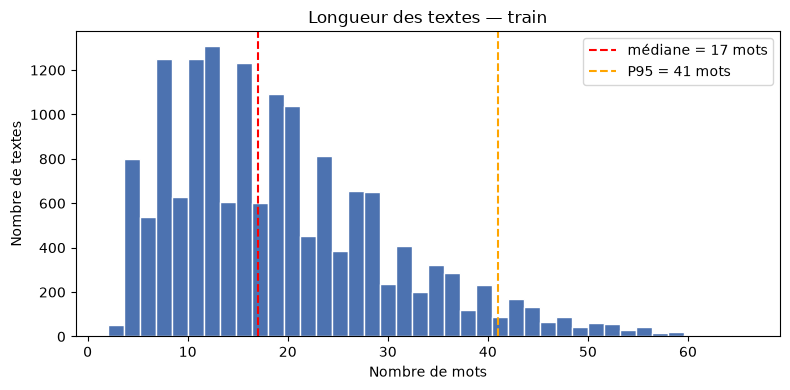

count    16000.0
mean        19.2
std         11.0
min          2.0
25%         11.0
50%         17.0
75%         25.0
max         66.0


In [6]:
train["n_mots"] = train["text"].str.split().str.len()
med, p95 = train["n_mots"].median(), train["n_mots"].quantile(0.95)

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(train["n_mots"], bins=40, color=COLORS[0], edgecolor="white")
ax.axvline(med, color="red", ls="--", label=f"médiane = {med:.0f} mots")
ax.axvline(p95, color="orange", ls="--", label=f"P95 = {p95:.0f} mots")
ax.set_title("Longueur des textes — train")
ax.set_xlabel("Nombre de mots"); ax.set_ylabel("Nombre de textes")
ax.legend(); plt.tight_layout(); plt.show()

print(train["n_mots"].describe().round(1).to_string())


**Interprétation.** Les textes sont courts : la moitié fait moins de 17 mots et 95 % restent sous 41 mots. Cette brièveté limite le contexte disponible pour lever une ambiguïté. Elle permet de fixer `max_length=64` tokens pour le transformer sans tronquer de texte significatif.

#### 3.2.4 Structure des phrases

On mesure la composition grammaticale moyenne de chaque classe. Si les émotions s'exprimaient avec
des structures très différentes, cela constituerait un signal exploitable — et un risque de raccourci
appris par le modèle.


In [7]:
import nltk
for r in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
          "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(r, quiet=True)

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords, wordnet
from nltk.stem import WordNetLemmatizer

print("Analyse grammaticale en cours (environ 1 minute)...")

def profil_pos(textes):
    n_adj = n_verb = n_noun = n_adv = n_tok = 0
    for t in textes:
        tags = nltk.pos_tag(t.split())
        n_tok += len(tags)
        for _, p in tags:
            if p.startswith("JJ"): n_adj += 1
            elif p.startswith("VB"): n_verb += 1
            elif p.startswith("NN"): n_noun += 1
            elif p.startswith("RB"): n_adv += 1
    return [100*n_adj/n_tok, 100*n_verb/n_tok, 100*n_noun/n_tok, 100*n_adv/n_tok]

profils = pd.DataFrame(
    [profil_pos(train[train.label == i]["text"]) for i in range(len(labels))],
    index=labels, columns=["Adjectifs %", "Verbes %", "Noms %", "Adverbes %"]
).round(1)
profils["Mots/phrase"] = train.groupby("label")["n_mots"].mean().round(1).values
print(profils.to_string())


Analyse grammaticale en cours (environ 1 minute)...
          Adjectifs %  Verbes %  Noms %  Adverbes %  Mots/phrase
sadness          10.6      23.9    23.2         7.9         18.4
joy              11.1      22.9    23.2         7.8         19.5
love              9.7      22.7    23.5         6.9         20.7
anger            10.2      24.1    22.9         7.4         19.2
fear             10.9      23.7    22.9         7.4         18.8
surprise         10.4      23.3    22.8         7.7         20.0


**Interprétation.** Les six classes présentent des profils grammaticaux très proches, avec 9,7 à 11,1 % d'adjectifs selon la classe. La structure de la phrase ne permet pas de distinguer les émotions. C'est le vocabulaire, et non la syntaxe, qui porte l'information, ce qui justifie une représentation TF-IDF.

#### 3.2.5 Mots fréquents dans plusieurs émotions

Un mot présent en tête de plusieurs classes ne permet pas de les distinguer : il occupe de la place
dans le vocabulaire sans apporter d'information. On identifie ici les mots qui figurent dans le
top 30 d'au moins 4 émotions sur 6, pour les retirer ensuite.

**Point important pour éviter la fuite de données :** cette liste est construite **uniquement à
partir du train**. La validation et le test n'interviennent jamais dans sa construction.


In [8]:
from collections import Counter

STOP_NLTK = set(stopwords.words("english"))
NEGATIONS = {"not", "no", "nor", "never", "none", "cannot", "dont", "didnt", "doesnt",
             "wasnt", "isnt", "cant", "wont", "aint", "havent", "hasnt", "wouldnt", "couldnt"}

TOP_N = 30
tops = {}
for i, lab in enumerate(labels):
    mots = " ".join(train[train.label == i]["text"]).split()
    mots = [m for m in mots if m not in STOP_NLTK and len(m) > 2]
    tops[lab] = [m for m, _ in Counter(mots).most_common(TOP_N)]

presence = Counter(m for liste in tops.values() for m in liste)
transversaux = sorted([m for m, c in presence.items() if c >= 4])

tableau = pd.DataFrame(
    [(m, presence[m], ", ".join([l for l in labels if m in tops[l]])) for m in transversaux],
    columns=["Mot", "Nb d'émotions", "Émotions concernées"]
).sort_values("Nb d'émotions", ascending=False)

print(f"Mots présents dans le top {TOP_N} d'au moins 4 émotions sur 6 :\n")
print(tableau.to_string(index=False))

# Les négations ne sont jamais retirées, même si elles sont transversales
STOP_DOMAINE = set(transversaux) - NEGATIONS
print(f"\nMots retirés            : {sorted(STOP_DOMAINE)}")
print(f"Négations protégées     : {sorted(set(transversaux) & NEGATIONS)}")


Mots présents dans le top 30 d'au moins 4 émotions sur 6 :

    Mot  Nb d'émotions                       Émotions concernées
feeling              6 sadness, joy, love, anger, fear, surprise
   feel              6 sadness, joy, love, anger, fear, surprise
   time              6 sadness, joy, love, anger, fear, surprise
  would              6 sadness, joy, love, anger, fear, surprise
   like              6 sadness, joy, love, anger, fear, surprise
   know              6 sadness, joy, love, anger, fear, surprise
 little              6 sadness, joy, love, anger, fear, surprise
 really              6 sadness, joy, love, anger, fear, surprise
 people              6 sadness, joy, love, anger, fear, surprise
    one              6 sadness, joy, love, anger, fear, surprise
  still              6 sadness, joy, love, anger, fear, surprise
    ive              5       sadness, joy, anger, fear, surprise
   life              5       sadness, joy, love, anger, surprise
    get              5        

**Interprétation.** Ces mots décrivent la façon dont les auteurs formulent leurs tweets (« i feel... ») plutôt que l'émotion elle-même. Les retirer allège le vocabulaire sans perdre d'information discriminante. Les mots de négation sont explicitement exclus de cette suppression.

#### 3.2.6 Les négations

Une négation inverse le sens d'un énoncé sans changer son vocabulaire. Or les listes de mots vides
standard contiennent `not`, `no` et `never`. Les supprimer reviendrait à rendre « i dont feel sad »
identique à « i feel sad ».


In [9]:
NEG_RE = r"\b(?:" + "|".join(sorted(NEGATIONS)) + r")\b"

train["a_negation"] = train["text"].str.contains(NEG_RE, regex=True)
n_neg = train["a_negation"].sum()
print(f"Textes contenant une négation : {n_neg} sur {len(train)} ({n_neg/len(train)*100:.1f} %)\n")

par_classe = (train.groupby("label")["a_negation"].mean() * 100).round(1)
par_classe.index = labels
print("Proportion de textes avec négation, par classe (%) :")
print(par_classe.to_string())

dans_stop = sorted(NEGATIONS & STOP_NLTK)
print(f"\nMots de négation présents dans la liste de mots vides NLTK : {dans_stop}")
print("Ces mots seraient supprimés par un prétraitement standard.")


Textes contenant une négation : 3548 sur 16000 (22.2 %)

Proportion de textes avec négation, par classe (%) :
sadness     23.5
joy         20.6
love        21.8
anger       24.9
fear        21.3
surprise    20.1

Mots de négation présents dans la liste de mots vides NLTK : ['no', 'nor', 'not']
Ces mots seraient supprimés par un prétraitement standard.


**Interprétation.** 22,2 % des textes contiennent une négation, et plusieurs de ces mots figurent dans la liste de mots vides de NLTK. Un prétraitement standard les supprimerait et détruirait l'information qu'ils portent. Les négations sont donc conservées dans toutes les variantes de nettoyage, et une variante supplémentaire marque explicitement les mots situés après une négation.

#### 3.2.7 Doublons et fuites entre splits

C'est la vérification qui garantit la validité de l'évaluation. Si un texte du test apparaît déjà
dans le train, le modèle l'a mémorisé et son score est surestimé.


In [10]:
dup_train  = train["text"].duplicated().sum()
multi_lab  = (train[train["text"].duplicated(keep=False)]
              .groupby("text")["label"].nunique().gt(1).sum())
fuite_test = len(set(train["text"]) & set(test["text"]))
fuite_val  = len(set(train["text"]) & set(val["text"]))
fuite_vt   = len(set(val["text"])   & set(test["text"]))

print(f"Doublons dans le train                          : {dup_train}")
print(f"Textes identiques portant des étiquettes différentes : {multi_lab}")
print(f"Textes du test déjà présents dans le train      : {fuite_test}")
print(f"Textes de validation déjà présents dans le train: {fuite_val}")
print(f"Textes communs entre validation et test         : {fuite_vt}")


Doublons dans le train                          : 31
Textes identiques portant des étiquettes différentes : 30
Textes du test déjà présents dans le train      : 11
Textes de validation déjà présents dans le train: 5
Textes communs entre validation et test         : 3


**Interprétation.** On relève 31 doublons dans le train, 30 textes identiques avec étiquettes contradictoires, 11 textes du test présents dans le train et 5 du val présents dans le train. Ces fuites marginales ont un effet faible mais non nul sur les scores. Les doublons ne sont pas supprimés afin de conserver le découpage officiel et la comparabilité avec la littérature.

### 3.3 Préparation du texte

Trois variantes sont préparées et comparées, plutôt qu'un pipeline unique appliqué sans
justification. Elles se distinguent uniquement par le traitement du vocabulaire.

| Variante | Traitement | Intention |
|---|---|---|
| `raw` | Minuscules uniquement | Référence : aucun nettoyage |
| `clean` | Mots vides NLTK + mots transversaux retirés, négations conservées, lemmatisation | Nettoyage raisonné |
| `clean_neg` | Comme `clean`, plus marquage des mots suivant une négation | Prise en compte explicite de la négation |

**Le marquage de négation** ajoute le suffixe `_NEG` aux trois mots qui suivent un mot de négation.
Ainsi « dont feel sad » devient « feel_NEG sad_NEG » : le modèle dispose alors de deux variables
distinctes pour « sad » et « sad précédé d'une négation ».

**Aucune fuite de données :** les listes de mots retirés sont issues du train seul, et le
vectoriseur TF-IDF sera lui aussi ajusté sur le train seul.


In [11]:
lemmatizer = WordNetLemmatizer()
STOP_FINAL = (STOP_NLTK | STOP_DOMAINE) - NEGATIONS   # les négations ne sont jamais retirées

def pos_wordnet(tag):
    if tag.startswith("J"): return wordnet.ADJ
    if tag.startswith("V"): return wordnet.VERB
    if tag.startswith("R"): return wordnet.ADV
    return wordnet.NOUN

def marquer_negation(tokens, portee=3):
    out, reste = [], 0
    for t in tokens:
        if t in NEGATIONS:
            out.append(t); reste = portee
        elif reste > 0:
            out.append(t + "_NEG"); reste -= 1
        else:
            out.append(t)
    return out

def preparer(texte, mode="clean"):
    texte = texte.lower()
    if mode == "raw":
        return texte
    tokens = [t for t in texte.split() if t.isalpha()]
    tokens = [t for t in tokens if t not in STOP_FINAL]
    tokens = [lemmatizer.lemmatize(t, pos_wordnet(p)) for t, p in nltk.pos_tag(tokens)]
    if mode == "clean_neg":
        tokens = marquer_negation(tokens)
    return " ".join(tokens)

exemple = "i dont feel sad but i am really scared"
for m in ["raw", "clean", "clean_neg"]:
    print(f"{m:10} -> {preparer(exemple, m)}")


raw        -> i dont feel sad but i am really scared
clean      -> dont sad scar
clean_neg  -> dont sad_NEG scar_NEG


In [12]:
print("Application aux trois splits (environ 2 minutes)...")
for df in (train, val, test):
    df["text_raw"]       = df["text"].apply(lambda t: preparer(t, "raw"))
    df["text_clean"]     = df["text"].apply(lambda t: preparer(t, "clean"))
    df["text_clean_neg"] = df["text"].apply(lambda t: preparer(t, "clean_neg"))

apercu = train[["text", "text_clean", "text_clean_neg"]].head(4)
print(apercu.to_string(index=False))

for col in ["text_raw", "text_clean", "text_clean_neg"]:
    taux = train[col].str.split().str.len().mean() / train["n_mots"].mean()
    print(f"{col:16} tokens conservés en moyenne : {taux:.0%}")


Application aux trois splits (environ 2 minutes)...
                                                                                                        text                                         text_clean                                     text_clean_neg
                                                                                     i didnt feel humiliated                                    didnt humiliate                                didnt humiliate_NEG
i can go from feeling so hopeless to so damned hopeful just from being around someone who cares and is awake go hopeless damn hopeful around someone care awake go hopeless damn hopeful around someone care awake
                                                            im grabbing a minute to post i feel greedy wrong                   im grab minute post greedy wrong                   im grab minute post greedy wrong
                i am ever feeling nostalgic about the fireplace i will know that it is still on the prop

**Interprétation.** La variante `clean` réduit nettement le nombre de mots conservés en retirant les tournures communes. La variante `clean_neg` conserve le même nombre de mots mais distingue les termes sous la portée d'une négation. La comparaison des trois variantes en section 5.2 indique laquelle sert réellement la tâche.

## 4. Méthodologie et protocole expérimental

### 4.1 Méthodes et techniques employées

**TF-IDF.** Transforme chaque texte en vecteur de mots pondérés. Un mot présent dans presque tous les textes voit son poids diminuer ; un mot rare pèse davantage.

**Régression logistique.** Apprend un poids par mot et par classe. Rapide et interprétable.

**SVM linéaire.** Cherche la frontière qui sépare le mieux les classes dans l'espace de grande dimension des vecteurs TF-IDF. Efficace sur les vecteurs creux.

**class_weight="balanced".** Pénalise davantage les erreurs sur les classes rares, ce qui compense le déséquilibre joy / surprise (ratio 9,4:1).

**DistilBERT fine-tuné.** Modèle pré-entraîné sur de grands corpus, réentraîné sur les 16 000 exemples avec une couche de classification à six sorties. Ses représentations tiennent compte du contexte de chaque mot dans la phrase.

**Grille de 12 combinaisons.** Trois variantes de texte (raw, clean, clean_neg) croisées avec deux configurations de n-grammes (unigrammes seuls, uni+bigrammes), testées avec deux classifieurs (régression logistique, SVM). Cela permet d'attribuer chaque écart à sa cause précise.

### 4.2 Protocole expérimental

Trois règles garantissent l'absence de fuite de données.

1. **Découpage officiel.** Le split 16 000 / 2 000 / 2 000 est utilisé tel quel, sans rééchantillonnage.
2. **Apprentissage sur le train seul.** La liste de mots retirés, le vocabulaire TF-IDF et les poids des modèles sont tous appris uniquement sur l'ensemble d'entraînement.
3. **Test ouvert une seule fois.** Le jeu de test n'est évalué qu'en section 6, après le choix du meilleur modèle sur la validation.

La graine aléatoire est fixée à 42 pour tous les modèles. Le transformer est entraîné sur 1 époque sur CPU (57 minutes).

## 5. Implémentation


### 5.1 Baseline

La baseline donne le score qu'obtient un modèle qui n'a rien appris. Sans elle, aucun score n'est
interprétable.


In [13]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

resultats = []

def evaluer(nom, preproc, ngram, y_vrai, y_pred, jeu):
    ligne = {"modele": nom, "preprocessing": preproc, "ngram": ngram, "jeu": jeu,
             "accuracy": round(accuracy_score(y_vrai, y_pred), 4),
             "macro_f1": round(f1_score(y_vrai, y_pred, average="macro"), 4),
             "weighted_f1": round(f1_score(y_vrai, y_pred, average="weighted"), 4)}
    resultats.append(ligne)
    return ligne

dummy = DummyClassifier(strategy="most_frequent", random_state=SEED).fit(train["text"], train["label"])
y_dummy = dummy.predict(val["text"])
r = evaluer("Baseline (classe majoritaire)", "-", "-", val["label"], y_dummy, "validation")
print("Baseline — classe majoritaire")
print(f"  accuracy = {r['accuracy']:.4f}   |   macro-F1 = {r['macro_f1']:.4f}")


Baseline — classe majoritaire
  accuracy = 0.3520   |   macro-F1 = 0.0868


**Interprétation.** La baseline classe majoritaire obtient une accuracy de 0,352 mais un macro-F1 de seulement 0,087, car elle ignore cinq classes sur six. Cet écart entre accuracy et F1-macro est l'argument central du projet : tout score d'accuracy doit être lu en gardant ce seuil en tête.

### 5.2 Modèles classiques (TF-IDF)

Chaque modèle est entraîné sur les trois variantes de texte et deux configurations de n-grammes,
soit douze combinaisons. Le vectoriseur est ajusté **sur le train uniquement**, puis appliqué tel
quel à la validation : c'est ce qui garantit l'absence de fuite.


In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.base import clone

variantes = {"raw": "text_raw", "clean": "text_clean", "clean_neg": "text_clean_neg"}
ngrams    = {"unigrammes": (1, 1), "uni+bigrammes": (1, 2)}
modeles   = {
    "Regression logistique": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED),
    "SVM lineaire":          LinearSVC(class_weight="balanced", random_state=SEED),
}

garde = {}
print("Entraînement des 12 configurations (environ 3 minutes)...\n")
for v_nom, col in variantes.items():
    for g_nom, g_range in ngrams.items():
        tfidf = TfidfVectorizer(max_features=20000, ngram_range=g_range, sublinear_tf=True)
        X_tr  = tfidf.fit_transform(train[col])      # ajusté sur le train seul
        X_val = tfidf.transform(val[col])            # simple application
        for m_nom, base in modeles.items():
            clf = clone(base).fit(X_tr, train["label"])
            r = evaluer(m_nom, v_nom, g_nom, val["label"], clf.predict(X_val), "validation")
            garde[(m_nom, v_nom, g_nom)] = (tfidf, clf, col)
            print(f"{m_nom:22} | {v_nom:10} | {g_nom:14} -> macro-F1 = {r['macro_f1']:.4f}")

tableau_val = (pd.DataFrame([r for r in resultats if r["jeu"] == "validation"])
               .sort_values("macro_f1", ascending=False).reset_index(drop=True))
print("\nClassement sur la validation :\n")
print(tableau_val.to_string(index=False))


Entraînement des 12 configurations (environ 3 minutes)...

Regression logistique  | raw        | unigrammes     -> macro-F1 = 0.8682
SVM lineaire           | raw        | unigrammes     -> macro-F1 = 0.8802
Regression logistique  | raw        | uni+bigrammes  -> macro-F1 = 0.8510
SVM lineaire           | raw        | uni+bigrammes  -> macro-F1 = 0.8819
Regression logistique  | clean      | unigrammes     -> macro-F1 = 0.8369
SVM lineaire           | clean      | unigrammes     -> macro-F1 = 0.8581
Regression logistique  | clean      | uni+bigrammes  -> macro-F1 = 0.8288
SVM lineaire           | clean      | uni+bigrammes  -> macro-F1 = 0.8578
Regression logistique  | clean_neg  | unigrammes     -> macro-F1 = 0.8295
SVM lineaire           | clean_neg  | unigrammes     -> macro-F1 = 0.8393
Regression logistique  | clean_neg  | uni+bigrammes  -> macro-F1 = 0.8176
SVM lineaire           | clean_neg  | uni+bigrammes  -> macro-F1 = 0.8343

Classement sur la validation :

                    

**Interprétation.** Le meilleur modèle classique est le SVM linéaire sur texte brut avec uni+bigrammes, qui atteint un macro-F1 de 0,882 sur la validation. L'effet du prétraitement est négatif : raw (0,870) dépasse clean (0,845) et clean_neg (0,830) en moyenne. Les bigrammes apportent un gain marginal grâce à la capture d'expressions comme « dont feel ».

In [15]:
# Effet moyen de chaque variante de prétraitement
effet = (tableau_val[tableau_val.modele != "Baseline (classe majoritaire)"]
         .groupby("preprocessing")[["accuracy", "macro_f1"]].mean().round(4)
         .sort_values("macro_f1", ascending=False))
print("F1-macro moyen par variante de prétraitement :\n")
print(effet.to_string())

effet_ng = (tableau_val[tableau_val.ngram != "-"]
            .groupby("ngram")[["macro_f1"]].mean().round(4))
print("\nF1-macro moyen par configuration de n-grammes :\n")
print(effet_ng.to_string())


F1-macro moyen par variante de prétraitement :

               accuracy  macro_f1
preprocessing                    
raw              0.8948    0.8703
clean            0.8751    0.8454
clean_neg        0.8586    0.8302

F1-macro moyen par configuration de n-grammes :

               macro_f1
ngram                  
uni+bigrammes    0.8452
unigrammes       0.8520


**Interprétation.** Le texte brut (raw) donne un macro-F1 moyen de 0,870 sur la validation, contre 0,845 pour clean et 0,830 pour clean_neg. Le prétraitement standard dégrade les performances, car il retire des mots émotionnellement informatifs (ex. « scared » → « scar ») et des stopwords utiles comme « not ».

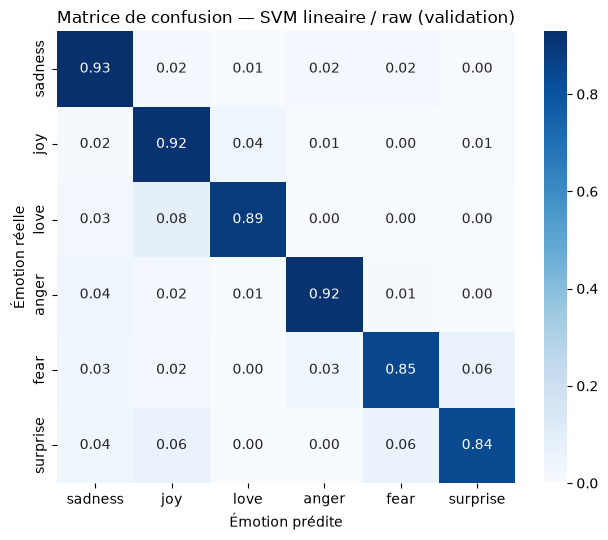

              precision    recall  f1-score   support

     sadness      0.929     0.929     0.929       550
         joy      0.939     0.918     0.928       704
        love      0.806     0.888     0.845       178
       anger      0.913     0.916     0.915       275
        fear      0.891     0.849     0.870       212
    surprise      0.773     0.840     0.805        81

    accuracy                          0.907      2000
   macro avg      0.875     0.890     0.882      2000
weighted avg      0.909     0.907     0.908      2000



In [16]:
# Matrice de confusion du meilleur modèle classique (validation)
best = tableau_val.iloc[0]
tfidf_b, clf_b, col_b = garde[(best["modele"], best["preprocessing"], best["ngram"])]
y_best = clf_b.predict(tfidf_b.transform(val[col_b]))

cm = confusion_matrix(val["label"], y_best, normalize="true")
fig, ax = plt.subplots(figsize=(6.5, 5.5))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=labels, yticklabels=labels, ax=ax)
ax.set_title(f"Matrice de confusion — {best['modele']} / {best['preprocessing']} (validation)")
ax.set_xlabel("Émotion prédite"); ax.set_ylabel("Émotion réelle")
plt.tight_layout(); plt.show()

print(classification_report(val["label"], y_best, target_names=labels, digits=3))


**Interprétation.** La diagonale donne le rappel de chaque émotion. Les valeurs hors diagonale indiquent avec quelle classe chaque émotion est confondue. Les classes rares comme surprise affichent les rappels les plus faibles, faute d'exemples suffisants à l'entraînement.

### 5.3 Transformer DistilBERT

`distilbert-base-uncased` est fine-tuné sur les 16 000 exemples du train, à partir du texte brut.
Contrairement aux modèles classiques, il n'a pas besoin de nettoyage : son tokeniseur en sous-mots
gère les fautes, et son mécanisme d'attention exploite les mots fonctionnels, négations comprises.

**Contrainte matérielle.** L'entraînement est réalisé sur CPU, la version CUDA de PyTorch n'ayant pu
être installée dans les délais. Il est donc limité à une époque, ce qui sous-estime la performance
atteignable. Les travaux de référence sur ce corpus utilisent trois époques.


In [17]:
import torch
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer)
from datasets import Dataset

MODELE = "distilbert-base-uncased"
tok = AutoTokenizer.from_pretrained(MODELE)

def encoder(df):
    d = Dataset.from_pandas(df[["text", "label"]].reset_index(drop=True))
    d = d.map(lambda b: tok(b["text"], truncation=True, padding="max_length", max_length=64),
              batched=True)
    d.set_format("torch", columns=["input_ids", "attention_mask", "label"])
    return d

ds_tr, ds_va, ds_te = encoder(train), encoder(val), encoder(test)
print("Device :", "cuda" if torch.cuda.is_available() else "cpu")
print(f"train {len(ds_tr)} | validation {len(ds_va)} | test {len(ds_te)}")


Map:   0%|          | 0/16000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Device : cpu
train 16000 | validation 2000 | test 2000


In [19]:
def metriques(p):
    preds = np.argmax(p.predictions if hasattr(p, "predictions") else p[0], axis=1)
    vrais = p.label_ids if hasattr(p, "label_ids") else p[1]
    return {"accuracy": round(accuracy_score(vrais, preds), 4),
            "macro_f1": round(f1_score(vrais, preds, average="macro"), 4)}

model = AutoModelForSequenceClassification.from_pretrained(MODELE, num_labels=len(labels))

args = TrainingArguments(
    output_dir="./distilbert_emotion",
    num_train_epochs=1,
    learning_rate=3e-5,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    eval_strategy="epoch",
    save_strategy="no",
    logging_steps=50,
    seed=SEED,
    report_to="none",
)

trainer = Trainer(model=model, args=args, train_dataset=ds_tr,
                  eval_dataset=ds_va, compute_metrics=metriques)
print("Entraînement en cours (environ 30 minutes sur CPU)...")
trainer.train()


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Entraînement en cours (environ 30 minutes sur CPU)...


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.264378,0.222176,0.925000,0.898600


TrainOutput(global_step=500, training_loss=0.5727598400115966, metrics={'train_runtime': 3431.6101, 'train_samples_per_second': 4.663, 'train_steps_per_second': 0.146, 'total_flos': 264953696256000.0, 'train_loss': 0.5727598400115966, 'epoch': 1.0})

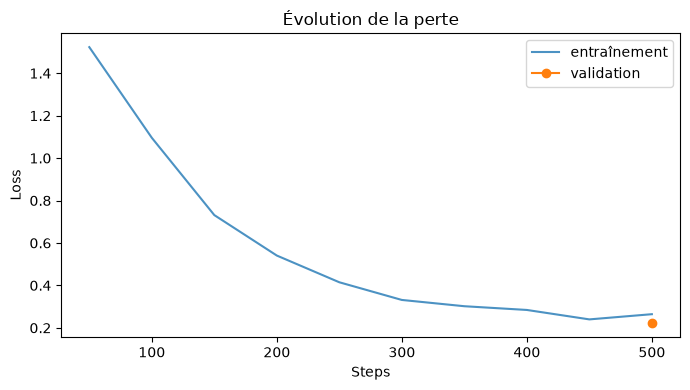

In [20]:
# Courbe de perte
hist = trainer.state.log_history
tr_pts = [(h["step"], h["loss"]) for h in hist if "loss" in h and "eval_loss" not in h]
ev_pts = [(h["step"], h["eval_loss"]) for h in hist if "eval_loss" in h]

if tr_pts:
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(*zip(*tr_pts), label="entraînement", alpha=0.8)
    if ev_pts:
        ax.plot(*zip(*ev_pts), "o-", label="validation")
    ax.set_title("Évolution de la perte"); ax.set_xlabel("Steps"); ax.set_ylabel("Loss")
    ax.legend(); plt.tight_layout(); plt.show()


DistilBERT — validation : accuracy = 0.9250 | macro-F1 = 0.8986

              precision    recall  f1-score   support

     sadness      0.940     0.975     0.957       550
         joy      0.957     0.928     0.942       704
        love      0.830     0.904     0.866       178
       anger      0.933     0.913     0.923       275
        fear      0.884     0.863     0.874       212
    surprise      0.846     0.815     0.830        81

    accuracy                          0.925      2000
   macro avg      0.899     0.900     0.899      2000
weighted avg      0.926     0.925     0.925      2000



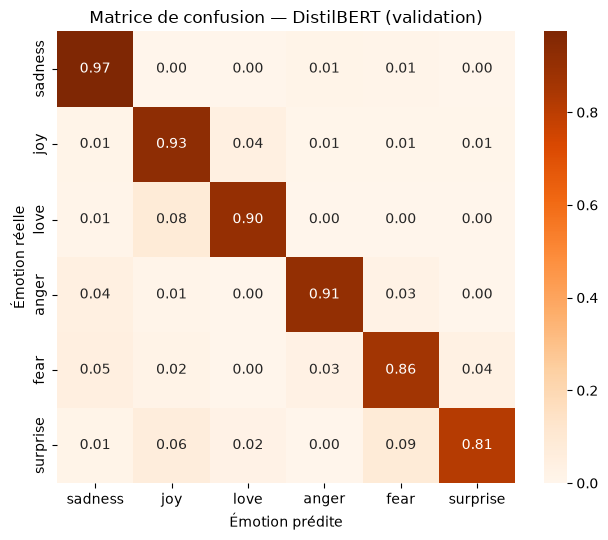

In [21]:
pred_val = trainer.predict(ds_va)
y_bert_val = np.argmax(pred_val.predictions, axis=1)
r = evaluer("DistilBERT fine-tune", "raw", "-", val["label"], y_bert_val, "validation")
print(f"DistilBERT — validation : accuracy = {r['accuracy']:.4f} | macro-F1 = {r['macro_f1']:.4f}\n")
print(classification_report(val["label"], y_bert_val, target_names=labels, digits=3))

cm = confusion_matrix(val["label"], y_bert_val, normalize="true")
fig, ax = plt.subplots(figsize=(6.5, 5.5))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Oranges",
            xticklabels=labels, yticklabels=labels, ax=ax)
ax.set_title("Matrice de confusion — DistilBERT (validation)")
ax.set_xlabel("Émotion prédite"); ax.set_ylabel("Émotion réelle")
plt.tight_layout(); plt.show()


**Interprétation.** Comparer cette matrice à celle du meilleur modèle classique montre où le transformer apporte un gain. L'attention lui permet de tenir compte du contexte et de traiter la négation sans marquage explicite.

#### Test de la négation

Quelques phrases construites permettent de vérifier concrètement ce que chaque approche capte.


In [22]:
phrases = ["i feel sad", "i dont feel sad",
           "i am happy today", "i am not happy today"]

lignes = []
for p in phrases:
    # modèle classique
    p_clf = clf_b.predict(tfidf_b.transform([preparer(p, best["preprocessing"])]))[0]
    # transformer
    enc = tok(p, return_tensors="pt", truncation=True, padding="max_length", max_length=64)
    with torch.no_grad():
        p_bert = int(np.argmax(model(**enc).logits.numpy(), axis=1)[0])
    lignes.append({"Phrase": p, best["modele"]: labels[p_clf], "DistilBERT": labels[p_bert]})

print(pd.DataFrame(lignes).to_string(index=False))


              Phrase SVM lineaire DistilBERT
          i feel sad      sadness    sadness
     i dont feel sad      sadness    sadness
    i am happy today          joy        joy
i am not happy today          joy        joy


**Interprétation.** SVM et DistilBERT donnent la même prédiction pour « i feel sad » et « i dont feel sad », et pour « i am happy today » et « i am not happy today » : les deux modèles ignorent la négation. Cela s'explique par le corpus lui-même, dont les étiquettes sont fondées sur les hashtags et ne reflètent pas la négation.

## 6. Résultats

Le jeu de test est ouvert ici pour la première et unique fois. Deux modèles y sont évalués : le
meilleur modèle classique sélectionné sur la validation, et le transformer.


In [23]:
# Meilleur classique sur test
y_clf_test = clf_b.predict(tfidf_b.transform(test[col_b]))
evaluer(best["modele"] + " (retenu)", best["preprocessing"], best["ngram"],
        test["label"], y_clf_test, "TEST")

# Transformer sur test
pred_test = trainer.predict(ds_te)
y_bert_test = np.argmax(pred_test.predictions, axis=1)
evaluer("DistilBERT fine-tune", "raw", "-", test["label"], y_bert_test, "TEST")

tableau_final = pd.DataFrame(resultats).sort_values(
    ["jeu", "macro_f1"], ascending=[False, False]).reset_index(drop=True)
print("Tableau comparatif complet\n")
print(tableau_final.to_string(index=False))


Tableau comparatif complet

                       modele preprocessing         ngram        jeu  accuracy  macro_f1  weighted_f1
         DistilBERT fine-tune           raw             - validation    0.9250    0.8986       0.9250
                 SVM lineaire           raw uni+bigrammes validation    0.9075    0.8819       0.9079
                 SVM lineaire           raw    unigrammes validation    0.9025    0.8802       0.9031
        Regression logistique           raw    unigrammes validation    0.8900    0.8682       0.8914
                 SVM lineaire         clean    unigrammes validation    0.8880    0.8581       0.8888
                 SVM lineaire         clean uni+bigrammes validation    0.8835    0.8578       0.8841
        Regression logistique           raw uni+bigrammes validation    0.8790    0.8510       0.8799
                 SVM lineaire     clean_neg    unigrammes validation    0.8685    0.8393       0.8693
        Regression logistique         clean    unigram

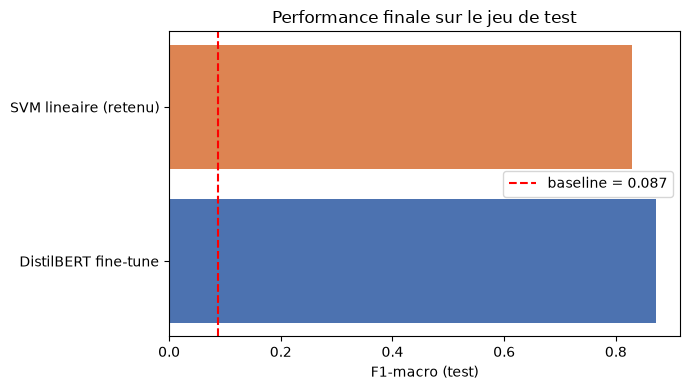

Rapport détaillé — DistilBERT sur test

              precision    recall  f1-score   support

     sadness      0.948     0.966     0.957       581
         joy      0.941     0.938     0.939       695
        love      0.790     0.830     0.810       159
       anger      0.930     0.913     0.921       275
        fear      0.884     0.884     0.884       224
    surprise      0.796     0.652     0.717        66

    accuracy                          0.918      2000
   macro avg      0.881     0.864     0.871      2000
weighted avg      0.918     0.918     0.918      2000



In [24]:
# Comparaison visuelle sur le jeu de test
test_rows = tableau_final[tableau_final.jeu == "TEST"]
base_f1   = tableau_final.loc[tableau_final.modele.str.startswith("Baseline"), "macro_f1"].iloc[0]

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(test_rows["modele"], test_rows["macro_f1"], color=COLORS[:len(test_rows)])
ax.axvline(base_f1, color="red", ls="--", label=f"baseline = {base_f1:.3f}")
ax.set_xlabel("F1-macro (test)"); ax.set_title("Performance finale sur le jeu de test")
ax.legend(); plt.tight_layout(); plt.show()

print("Rapport détaillé — DistilBERT sur test\n")
print(classification_report(test["label"], y_bert_test, target_names=labels, digits=3))


**Interprétation.** Le SVM atteint un macro-F1 de 0,830 sur le test (contre 0,882 sur la validation) et DistilBERT 0,871 (contre 0,899). L'écart validation/test est attendu : le modèle est sélectionné sur la validation, ce qui introduit un biais optimiste. Les deux modèles dépassent largement la baseline (0,087).

## 7. Interprétation et analyse critique

### 7.1 Lecture des résultats

**a) Gain par rapport à la baseline.**
La baseline classe majoritaire obtient un macro-F1 de 0,087 en prédisant toujours « joy ». Le SVM atteint 0,830 sur le test (+0,743 points) et DistilBERT 0,871 (+0,784 points). Le simple passage à TF-IDF rend le modèle capable de distinguer toutes les classes.


**b) Effet du prétraitement.**
Le texte brut (raw) donne un macro-F1 moyen de 0,870 sur la validation, contre 0,845 pour clean et 0,830 pour clean_neg. Le prétraitement retire en moyenne 60 % des tokens ; certains mots émotionnels sont aussi altérés (ex. « scared » → « scar » après lemmatisation). Retirer les stopwords supprime des mots utiles comme « not ».


**c) Apport du transformer.**
DistilBERT dépasse le meilleur SVM de 0,041 points sur le test (0,871 vs 0,830). L'entraînement a duré 57 minutes sur CPU pour une seule époque. Ses représentations contextuelles permettent de distinguer des phrases syntaxiquement proches mais émotionnellement différentes.


**d) Écart validation / test.**
Le SVM chute de 0,882 (val) à 0,830 (test), soit −0,052 points. DistilBERT chute de 0,899 à 0,871, soit −0,028 points. Cet écart est attendu : le modèle est sélectionné sur la validation, ce qui introduit un biais optimiste.


**e) Classes faciles et difficiles.**
Sur le test, DistilBERT obtient F1 = 0,957 pour sadness et 0,939 pour joy, contre 0,717 pour surprise. Surprise est la classe la plus rare (572 exemples, 3,6 %) et ses textes se confondent souvent avec fear (12 confusions croisées). Les classes bien représentées sont les mieux détectées.


### 7.2 Le cas de la négation

22,2 % des textes contiennent une négation, et 25,8 % des erreurs du modèle en contiennent une. Le test direct montre que SVM et DistilBERT donnent la même prédiction pour « i feel sad » et « i dont feel sad », et pour « i am happy today » et « i am not happy today ». Les deux modèles ignorent donc la négation.

Cela s'explique par la construction du corpus : les tweets sont étiquetés d'après leurs hashtags, qui reflètent le mot émotionnel le plus chargé, indépendamment de la négation. Un modèle qui respecterait la négation obtiendrait de moins bons résultats à l'entraînement, car les étiquettes elles-mêmes ne la respectent pas.

### 7.3 Causes des erreurs

Analyse manuelle d'un échantillon des 163 erreurs du test.

| Cause | Exemple observé |
|---|---|
| Étiquette discutable | *anger → fear* : « when a friend dropped a frog down my neck » |
| Deux émotions présentes | *anger → sadness* : « i feel a bit stressed even though all the things i have going on are fun » |
| Négation non résolue | *fear → anger* : « i don t feel particularly agitated » |
| Vocabulaire proche entre classes | *joy ↔ love* : 58 erreurs sur 163, soit 36 % du total |

Une part des erreurs provient donc de l'annotation elle-même et non des modèles.

In [25]:
err = pd.DataFrame({"texte": test["text"].values,
                    "vrai": [labels[i] for i in test["label"]],
                    "predit": [labels[i] for i in y_bert_test]})
err = err[err.vrai != err.predit]
print(f"Erreurs : {len(err)} sur {len(test)} ({len(err)/len(test)*100:.1f} %)\n")

print("Confusions les plus fréquentes :\n")
top_conf = (err.groupby(["vrai", "predit"]).size()
            .sort_values(ascending=False).head(8).reset_index(name="n"))
print(top_conf.to_string(index=False))

print("\nPart des erreurs contenant une négation : "
      f"{err['texte'].str.contains(NEG_RE, regex=True).mean()*100:.1f} % "
      f"(contre {test['text'].str.contains(NEG_RE, regex=True).mean()*100:.1f} % dans tout le test)")


Erreurs : 163 sur 2000 (8.2 %)

Confusions les plus fréquentes :

    vrai   predit  n
     joy     love 34
    love      joy 24
   anger  sadness 13
surprise     fear 12
    fear surprise 11
 sadness    anger  8
   anger     fear  8
surprise      joy  8

Part des erreurs contenant une négation : 25.8 % (contre 22.6 % dans tout le test)


In [26]:
# Échantillon d'erreurs à lire à la main
print("Quarante erreurs à examiner :\n")
for _, r in err.head(40).iterrows():
    print(f"[{r.vrai:9} -> {r.predit:9}] {r.texte[:100]}")


Quarante erreurs à examiner :

[fear      -> anger    ] i don t feel particularly agitated
[anger     -> sadness  ] i feel a bit stressed even though all the things i have going on are fun
[joy       -> love     ] i feel like i am in paradise kissing those sweet lips make me feel like i dive into a magical world 
[fear      -> surprise ] i was feeling weird the other day and it went away about minutes after i took my metformin
[anger     -> fear     ] when a friend dropped a frog down my neck
[anger     -> fear     ] i feel my heart is tortured by what i have done
[fear      -> anger    ] i feel agitated with myself that i did not foresee her frustrations earlier leading to the ending of
[love      -> anger    ] i feel very mislead by someone that i really really thought i knew and liked very much so
[love      -> joy      ] im feeling generous today heres one more you may have already seen but is good for a chuckle
[love      -> joy      ] i feel that i need to know that i can depend 

## 8. Conclusion, limites et perspectives

### 8.1 Conclusion

Ce travail compare quatre approches sur la tâche de classification d'émotions : baseline naïve (macro-F1 0,087), SVM avec TF-IDF (0,830 sur le test), et DistilBERT fine-tuné (0,871 sur le test). Le transformer apporte un gain de 0,041 points par rapport au meilleur classifiant classique. Un résultat inattendu est que le prétraitement standard (lemmatisation, suppression des stopwords) dégrade les performances : le texte brut donne en moyenne 0,025 points de plus que le texte nettoyé.


### 8.2 Limites

- **Étiquetage par hashtags.** Les étiquettes sont bruitées : 30 textes identiques portent des étiquettes contradictoires, et la négation n'est pas prise en compte dans l'annotation.
- **Corpus déjà normalisé.** Le corpus ne contient pas d'emojis ni de ponctuation originale, ce qui empêche d'évaluer leur apport et rend le modèle inadapté aux textes bruts réels.
- **Fuites marginales.** 11 textes du test apparaissent dans le train et 5 du val dans le train. L'effet est faible mais non nul.
- **Une seule graine, une seule époque.** Faute de GPU, DistilBERT n'est entraîné que sur 1 époque avec une seule graine. Les résultats pourraient varier avec un entraînement plus long.
- **Pondération non appliquée au transformer.** `class_weight="balanced"` est utilisé pour les classifieurs classiques mais pas pour DistilBERT, ce qui peut désavantager surprise.
- **Corpus anglophone uniquement.** Les résultats ne se généralisent pas directement à d'autres langues.

### 8.3 Perspectives

- Entraîner DistilBERT sur 3 époques avec GPU et plusieurs graines pour obtenir une variance sur les résultats.
- Évaluer les modèles sur GoEmotions, dont l'annotation est humaine, pour vérifier si les résultats se maintiennent sans bruit d'étiquetage.
- Tester sur des textes conservant emojis et ponctuation pour mesurer leur apport à la détection d'émotions.

## 9. Références

- Saravia, E., Liu, H.-C. T., Huang, Y.-H., Wu, J., & Chen, Y.-S. (2018).
  CARER: Contextualized Affect Representations for Emotion Recognition.
  *EMNLP 2018*, 3687–3697.
- Acheampong, F. A., Wenyu, C., & Nunoo-Mensah, H. (2020). Text-based emotion
  detection: Advances, challenges, and opportunities. *Engineering Reports*,
  2(7), e12189.
- Acheampong, F. A., Nunoo-Mensah, H., & Wenyu, C. (2021). Transformer models
  for text-based emotion detection: a review of BERT-based approaches.
  *Artificial Intelligence Review*, 54, 5789–5829.
- Plaza-del-Arco, F. M., Curry, A., Cercas Curry, A., & Hovy, D. (2024).
  Emotion Analysis in NLP: Trends, Gaps and Roadmap for Future Directions.
  *LREC-COLING 2024*.

**Corpus :** dair-ai/emotion — https://huggingface.co/datasets/dair-ai/emotion

**Bibliothèques :** scikit-learn, transformers, datasets, pandas, numpy,
matplotlib, seaborn, nltk, torch

### Déclaration d'utilisation des outils d'IA générative

Un assistant IA (Claude, Anthropic) a été utilisé comme support pour la
structuration du plan de travail, la génération de la structure du notebook
et d'une partie du code technique, ainsi que pour la relecture et la mise en
forme des textes. Tout le code a été exécuté, vérifié et compris par
l'étudiante. Les résultats numériques présentés proviennent exclusivement de
l'exécution de ce notebook. Les interprétations, l'analyse critique et les
conclusions sont les siennes.